### Importing libraries

In [1]:
import pathlib, zipfile
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Uploading Dataset, and the nature of the dataset

In [2]:
# Locate heart.csv whether this runs in Colab or in a local clone of the repo.
def find_heart_csv():
    roots = [pathlib.Path.cwd(), pathlib.Path("/content"),
             pathlib.Path("/content/ECS171-Project")]
    for r in roots:
        for p in (r / "heart.csv", r / "data" / "heart.csv"):
            if p.exists():
                return p
    for r in roots:                      # not unpacked yet -> extract the repo zip
        z = r / "heartfailure_dataset.zip"
        if z.exists():
            zipfile.ZipFile(z).extractall(r / "data")
            return r / "data" / "heart.csv"
    raise FileNotFoundError("heart.csv not found - upload it or clone the repo")

CSV = find_heart_csv()
print("loading", CSV)
df = pd.read_csv(CSV)

print("=== 1. SHAPE / DTYPES ===")
print(df.shape)
print(df.dtypes.to_string())

print("\n=== 2. MISSING (explicit NaN) ===")
print(df.isna().sum().to_string())

print("\n=== 3. DUPLICATES ===")
print("full-row duplicates:", df.duplicated().sum())

#dropping the target column to isolate
features = df.columns.drop("HeartDisease") 
print("duplicate feature-rows (ignoring target):", df.duplicated(subset=features).sum())
print("\nfeatures:", features)

=== 1. SHAPE / DTYPES ===
(918, 12)
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64

=== 2. MISSING (explicit NaN) ===
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0

=== 3. DUPLICATES ===
full-row duplicates: 0
duplicate feature-rows (ignoring target): 0

features: Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope'],
      dtype='str')


---

### Summary Stats

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


### Valuable Finding  to be used during preprocessing  
RestingBP min = 0.0: A patient cannot have a blood pressure of 0 mm Hg while taking an exercise test.  
Cholesterol min = 0.0 (and 25th percentile is low): Serum cholesterol cannot be 0 mg/dL. In this dataset, 0 indicates unrecorded measurements. These need imputation (median/KNN) before being fed directly to a model.  
preprocessing must treat the 0s in RestingBP and Cholesterol as missing values.  

Oldpeak min = -2.6: ST depression is typically non-negative, but negative values represent ST elevation. This is physiologically valid, but ensure standard scalers or tree splits account for this distribution.

HeartDisease
1    508
0    410
Name: count, dtype: int64

Proportions:
 HeartDisease
1    0.553
0    0.447
Name: count, dtype: float64


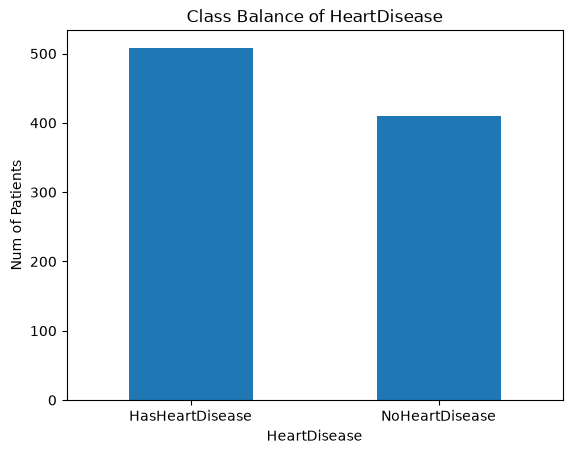

In [4]:
counts = df["HeartDisease"].value_counts()
print(counts)
print("\nProportions:\n", (counts/ len(df)).round(3))

ax = counts.rename({0: "NoHeartDisease", 1: "HasHeartDisease"}).plot(kind= "bar", rot=0)
ax.set_ylabel("Num of Patients"); ax.set_title("Class Balance of HeartDisease")
plt.show()

* It does not have severe class imbalance. However, some metrics such as accuracy will treat FP and FN as equally bad. Recall fits this dataset more as it is critical not to miss the FNs.

### Distributions and Outliers

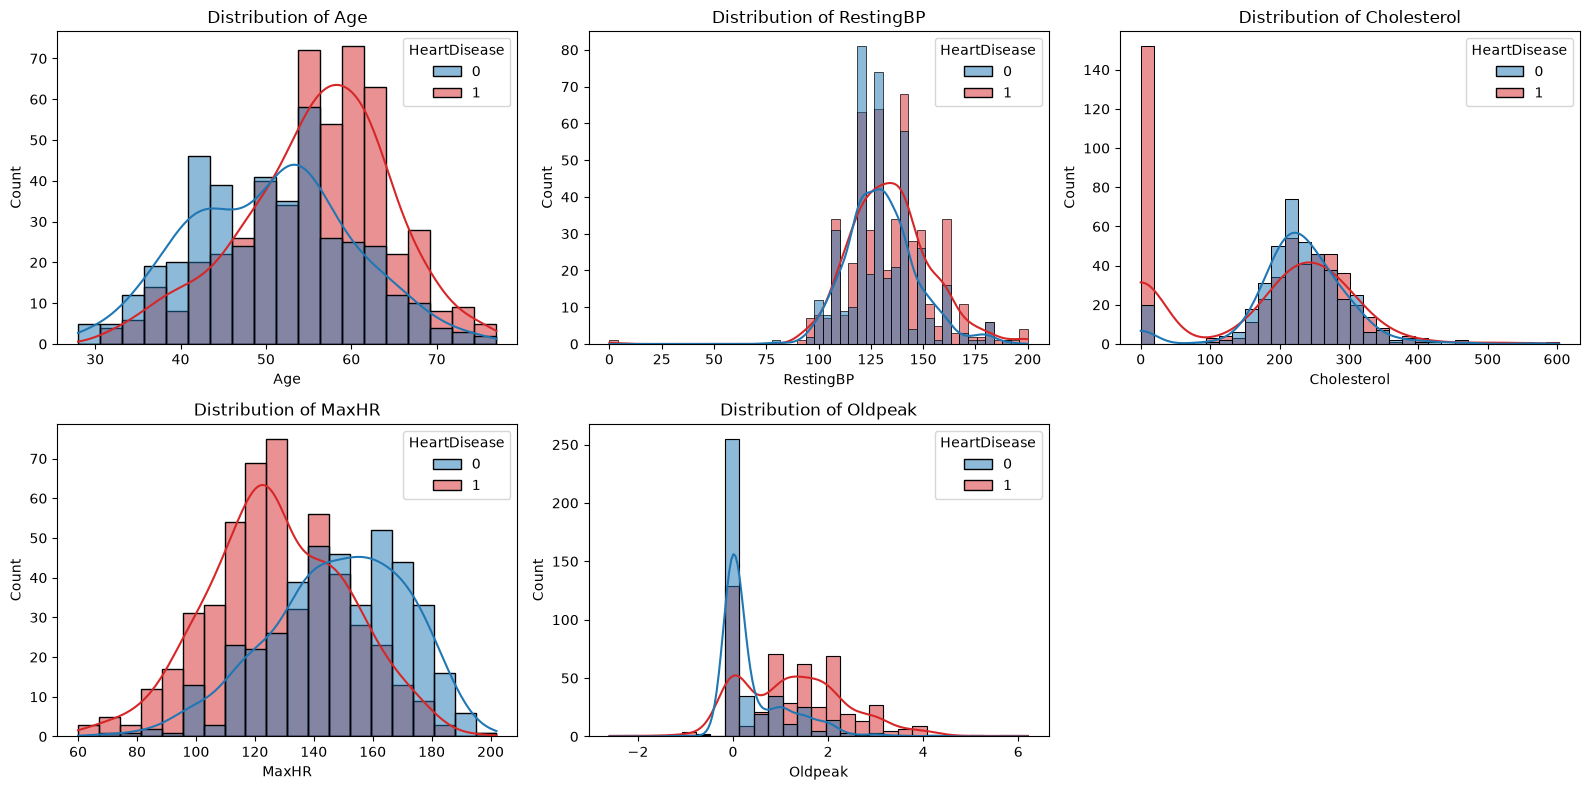

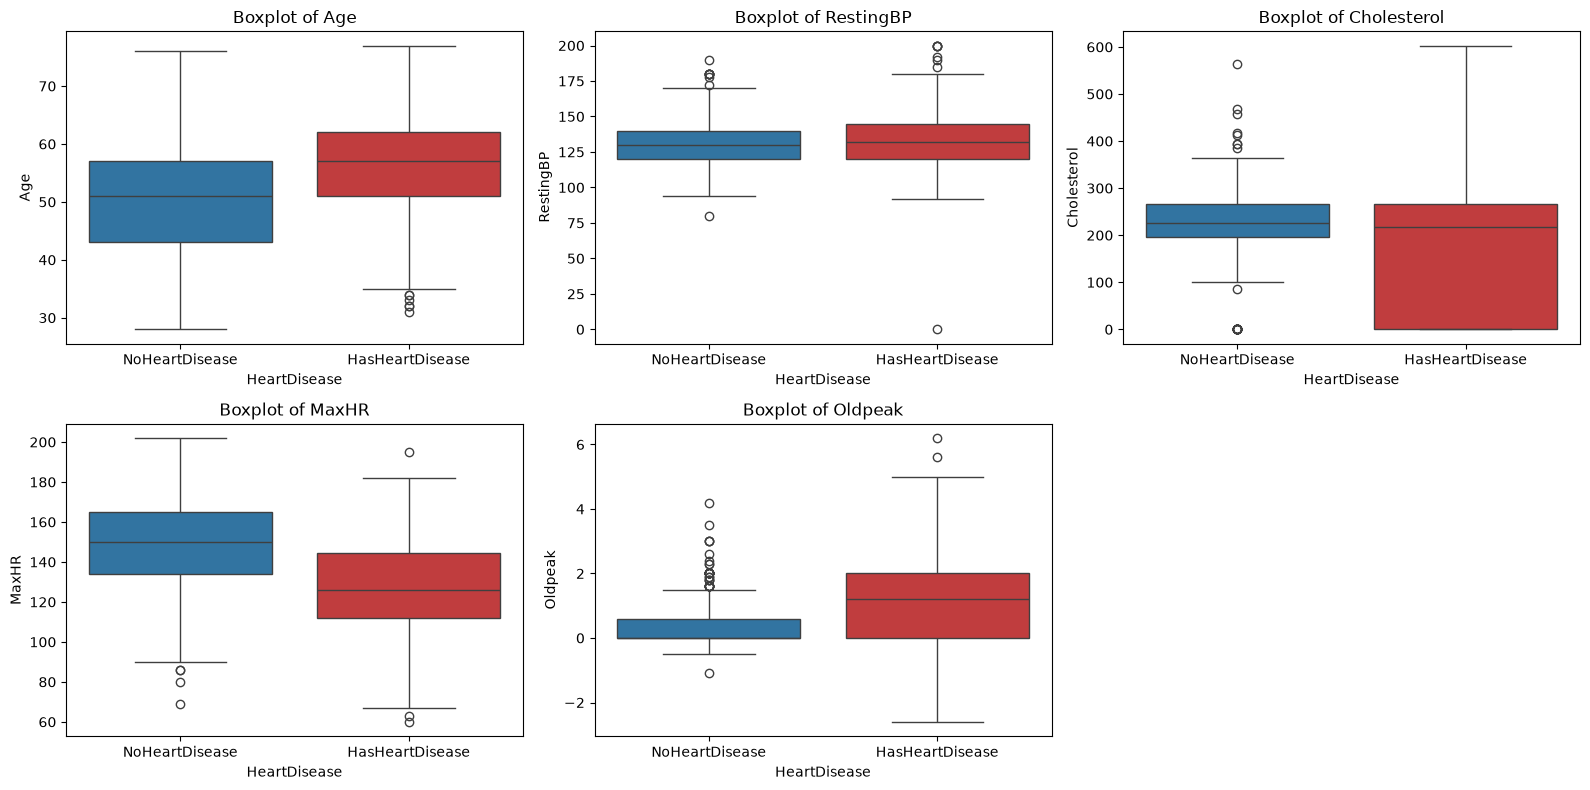

In [5]:
# 5 continuous numerical features
num_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

# 1. Histograms with KDE
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.histplot(
        data=df,
        x=col,
        hue="HeartDisease",
        kde=True,
        ax=axes[i],
        palette={0: "tab:blue", 1: "tab:red"}
    )
    axes[i].set_title(f"Distribution of {col}")

fig.delaxes(axes[5])  # Remove unused 6th subplot
plt.tight_layout()
plt.show()

# Boxplots by Target
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(
        data=df,
        x="HeartDisease",
        y=col,
        hue="HeartDisease",
        legend=False,
        ax=axes[i],
        palette={0: "tab:blue", 1: "tab:red"}
    )
    axes[i].set_title(f"Boxplot of {col}")
    # Eliminates the UserWarning by setting ticks and labels together
    axes[i].set_xticks([0, 1], labels=["NoHeartDisease", "HasHeartDisease"])

fig.delaxes(axes[5])  # Remove unused 6th subplot
plt.tight_layout()
plt.show()

### Categorial Values plots

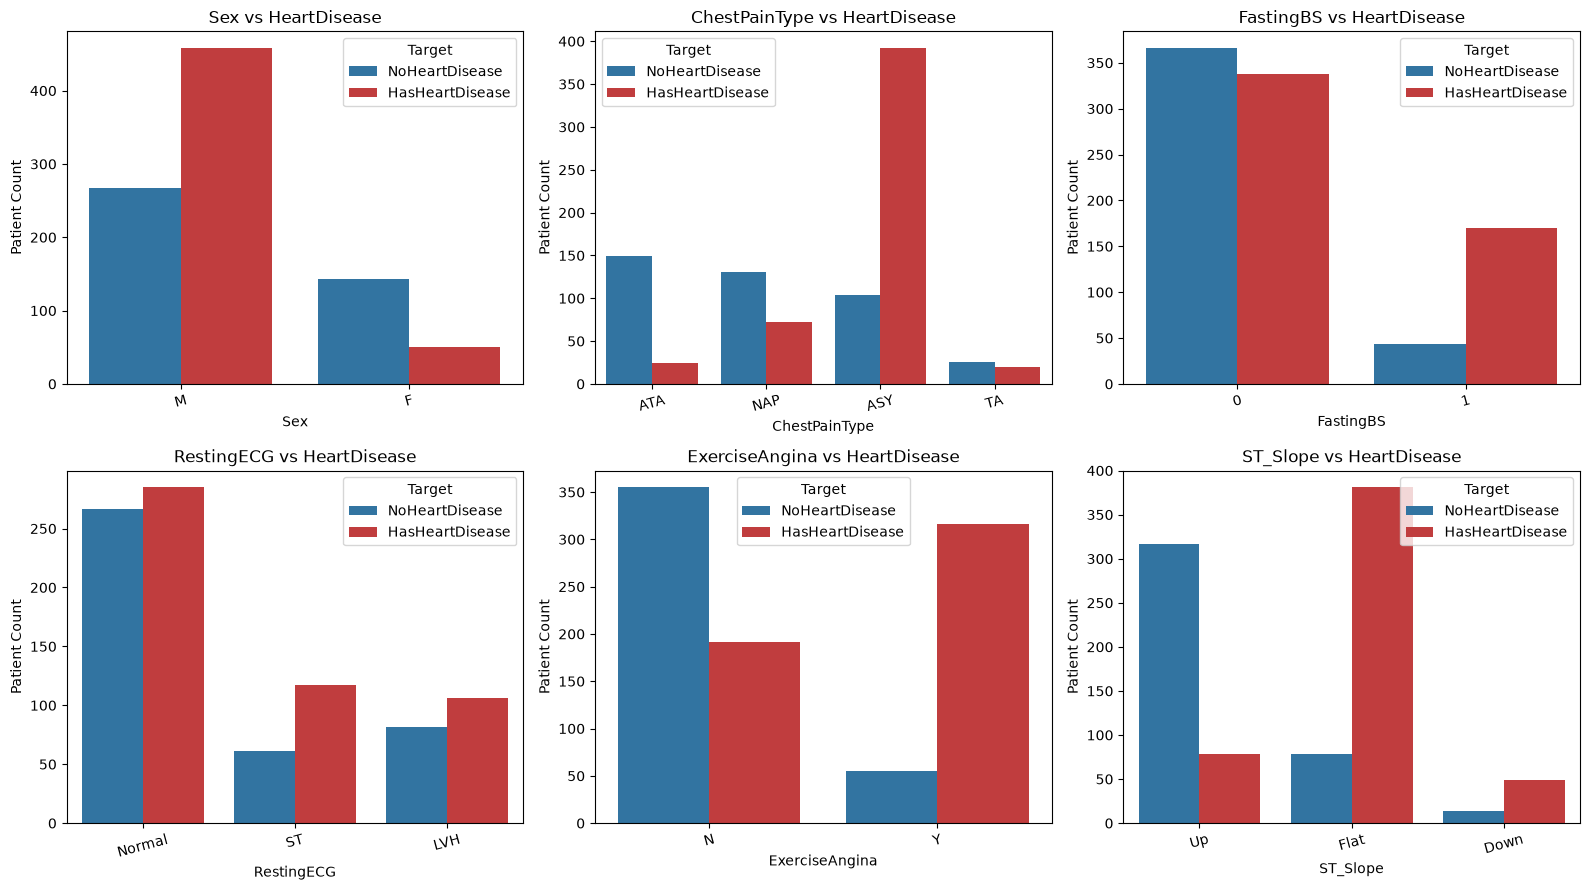

In [6]:
# 6 categorical and binary features
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="HeartDisease",
        ax=axes[i],
        palette={0: "tab:blue", 1: "tab:red"}
    )
    axes[i].set_title(f"{col} vs HeartDisease")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Patient Count")
    axes[i].tick_params(axis="x", rotation=15)
    
    # Custom legend labels
    axes[i].legend(title="Target", labels=["NoHeartDisease", "HasHeartDisease"])

plt.tight_layout()
plt.show()

### Correlation HeatMap

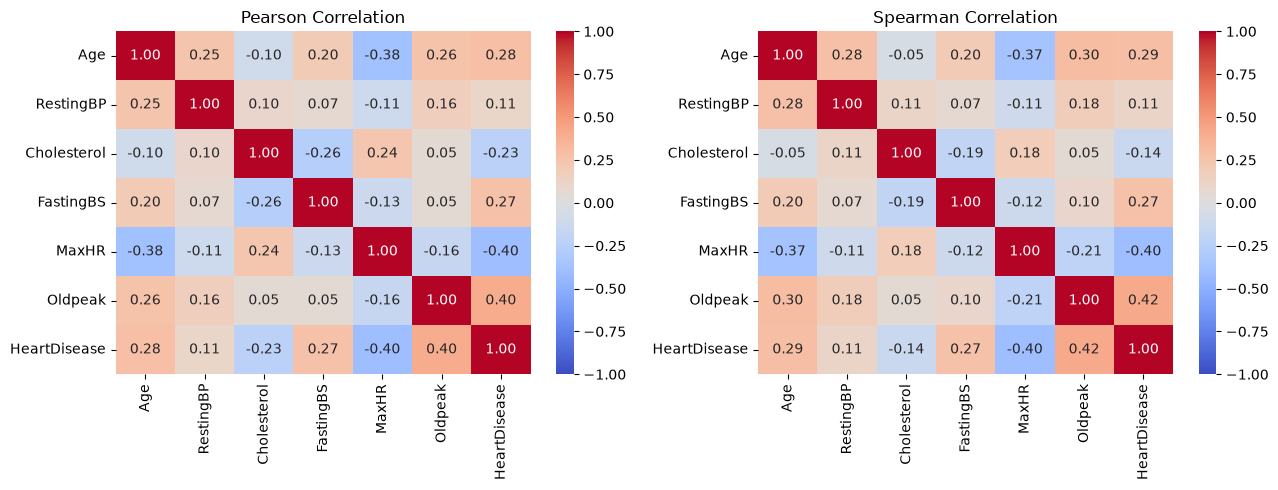

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pearson correlation (linear relationships)
corr_pearson = df.corr(method="pearson", numeric_only=True)
sns.heatmap(
    corr_pearson, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    ax=axes[0]
)
axes[0].set_title("Pearson Correlation")

# Spearman correlation (monotonic / non-linear relationships)
corr_spearman = df.corr(method="spearman", numeric_only=True)
sns.heatmap(
    corr_spearman, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    ax=axes[1]
)
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()